# Comparing the five affinity scores

This notebook compares max-site, ln TBA, TBA per window, TRAP occupancy and the steric-exclusion partition function on the same sequences. It reports AUROC per score and per λ, so the default score can be chosen from data instead of assumed.

**By default it runs offline on a synthetic benchmark.** Positives carry PWM-sampled sites of graded affinity: some have one strong site, others a cluster of weak sites. Negatives are background sequence with the same composition. A synthetic benchmark checks that the pipeline works and shows how the scores differ in principle. It is **not** evidence about real binding.

For a real test, set `GENOME` and `PEAKS_BED` in the next cell. Positives are then summit ±100 bp of the top 500 peaks, and controls are 200 bp starting 300 bp downstream of each peak, as PWMEval does.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seqaffinity as sa
from seqaffinity.genome import read_bed_sequences

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PWM_PATH = ROOT / "tests" / "fixtures" / "MA0004.1.jaspar"   # Arnt (CACGTG)

# --- Real data (optional): set both to switch from the synthetic benchmark. ---
GENOME = None      # e.g. "hg38.fa.gz"
PEAKS_BED = None   # narrowPeak/BED with summit offset in column 10, sorted by signal
N_PEAKS = 500

LAMBDAS = [0.5, 0.7, 1.0, 1.5]
SCORE_COLS = ["max_score", "ln_tba", "tba_per_window", "trap", "partition_fn"]
pwm = sa.load_pwm(PWM_PATH)
pwm.name, pwm.width

('MA0004.1', 6)

## Sequences

In [2]:
rng = np.random.default_rng(2026)
BG = np.array([0.295, 0.205, 0.205, 0.295])   # ~41% GC
probs = pwm.counts / pwm.counts.sum(axis=1, keepdims=True)

def background_seq(n):
    return "".join(rng.choice(list("ACGT"), size=n, p=BG))

def sample_site(temperature=1.0):
    # Sample a site from the PWM; temperature > 1 flattens it (weaker sites).
    p = probs ** (1 / temperature)
    p = (p + 1e-3) / (p + 1e-3).sum(axis=1, keepdims=True)
    site = "".join(rng.choice(list("ACGT"), p=row) for row in p)
    return site if rng.random() < 0.5 else site[::-1].translate(str.maketrans("ACGT", "TGCA"))

def plant(seq, sites):
    s = list(seq)
    for site in sites:
        pos = rng.integers(0, len(s) - len(site))
        s[pos:pos + len(site)] = site
    return "".join(s)

def synthetic(n=500, L=200):
    pos = []
    for i in range(n):
        if i % 2 == 0:   # one strong site
            pos.append(plant(background_seq(L), [sample_site(1.0)]))
        else:            # a cluster of weak sites
            pos.append(plant(background_seq(L), [sample_site(3.0) for _ in range(rng.integers(3, 7))]))
    neg = [background_seq(L) for _ in range(n)]
    return pos, neg

def from_peaks(genome, bed, n):
    peaks = pd.read_csv(bed, sep="\t", header=None, comment="#").head(n)
    summit = peaks[1] + (peaks[9] if peaks.shape[1] > 9 else (peaks[2] - peaks[1]) // 2)
    tmp = Path("_peaks_tmp.bed")
    rows = [(c, s - 100, s + 100, f"p{i}") for i, (c, s) in enumerate(zip(peaks[0], summit))]
    rows += [(c, e + 300, e + 500, f"n{i}") for i, (c, e) in enumerate(zip(peaks[0], peaks[2]))]
    pd.DataFrame(rows).to_csv(tmp, sep="\t", header=False, index=False)
    recs = read_bed_sequences(genome, tmp)
    tmp.unlink()
    return [s for k, s in recs if k.startswith("p")], [s for k, s in recs if k.startswith("n")]

if GENOME and PEAKS_BED:
    positives, negatives = from_peaks(GENOME, PEAKS_BED, N_PEAKS)
    SOURCE = f"ChIP peaks: {PEAKS_BED}"
else:
    positives, negatives = synthetic()
    SOURCE = "synthetic benchmark"
seqs = [(f"pos{i}", s) for i, s in enumerate(positives)] + [(f"neg{i}", s) for i, s in enumerate(negatives)]
labels = np.array([1] * len(positives) + [0] * len(negatives))
SOURCE, len(positives), len(negatives)

('synthetic benchmark', 500, 500)

## Scores across λ

In [3]:
def auroc(score, y):
    # Mann–Whitney AUROC with average ranks for ties; NaN scores rank lowest.
    s = pd.Series(score).fillna(-np.inf)
    r = s.rank(method="average").to_numpy()
    n1, n0 = y.sum(), len(y) - y.sum()
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

bg = ",".join(str(x) for x in BG)
tables = {lam: sa.score_sequences(pwm, seqs, lam=lam, background=bg) for lam in LAMBDAS}
summary = pd.DataFrame(
    {lam: {c: auroc(tables[lam][c].to_numpy(), labels) for c in SCORE_COLS} for lam in LAMBDAS}
)
summary.index.name = "score"
summary.columns = [f"lambda={l}" for l in LAMBDAS]
summary.attrs["source"] = SOURCE
summary.round(3)

,lambda=0.5,lambda=0.7,lambda=1.0,lambda=1.5
score,,,,
max_score,0.973,0.973,0.973,0.973
ln_tba,0.982,0.982,0.981,0.975
tba_per_window,0.982,0.982,0.981,0.975
trap,0.982,0.982,0.981,0.975
partition_fn,0.982,0.982,0.981,0.975


In [4]:
out = ROOT / "notebooks" / "auroc_summary.csv"
with open(out, "w") as fh:
    fh.write(f"# source={SOURCE}; pwm={pwm.name}; R0=TRAP default; background={bg}\n")
    summary.to_csv(fh)
print("wrote", out.relative_to(ROOT))
best = summary.stack().idxmax()
print(f"best: {best[0]} at {best[1]} (AUROC {summary.stack().max():.3f})")

wrote notebooks/auroc_summary.csv
best: partition_fn at lambda=0.7 (AUROC 0.982)


## Pairwise relationships (λ = 0.7)

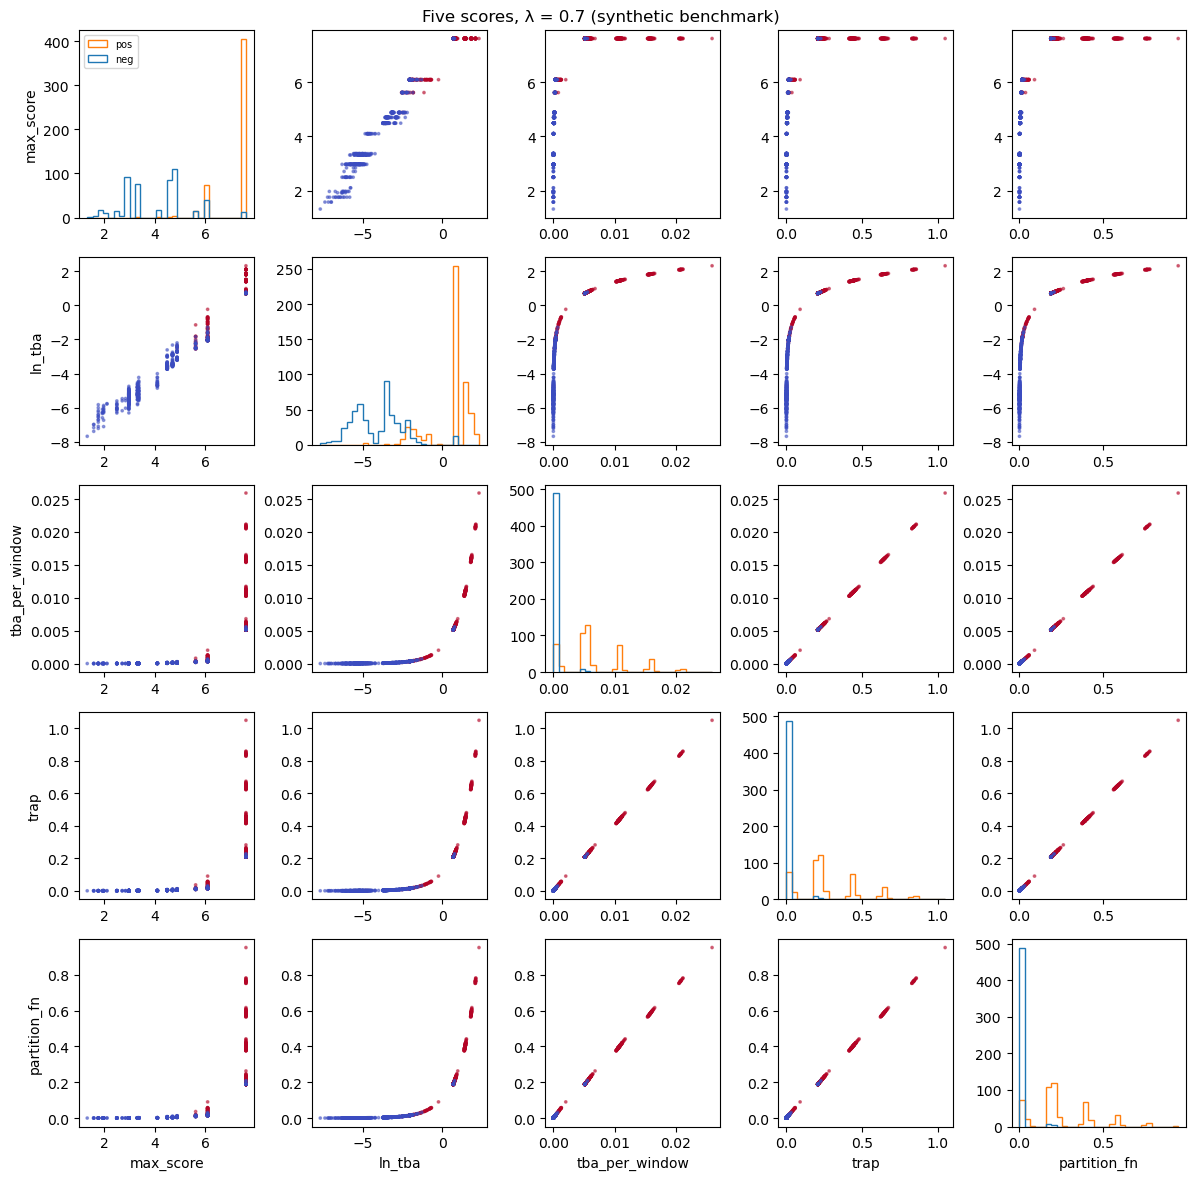

In [5]:
df = tables[0.7]
fig, axes = plt.subplots(len(SCORE_COLS), len(SCORE_COLS), figsize=(12, 12))
for i, a in enumerate(SCORE_COLS):
    for j, b in enumerate(SCORE_COLS):
        ax = axes[i, j]
        if i == j:
            ax.hist([df[a][labels == 0], df[a][labels == 1]], bins=30, label=["neg", "pos"], histtype="step")
        else:
            ax.scatter(df[b], df[a], c=labels, s=3, cmap="coolwarm", alpha=0.5)
        if i == len(SCORE_COLS) - 1:
            ax.set_xlabel(b)
        if j == 0:
            ax.set_ylabel(a)
axes[0, 0].legend(fontsize=7)
fig.suptitle(f"Five scores, λ = 0.7 ({SOURCE})")
fig.tight_layout()

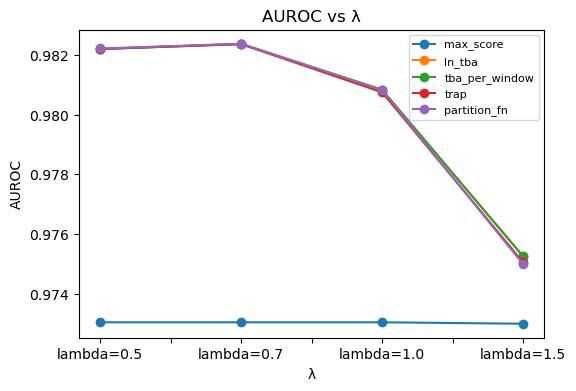

In [6]:
ax = summary.T.plot(marker="o", figsize=(6, 4))
ax.set_ylabel("AUROC")
ax.set_xlabel("λ")
ax.set_title("AUROC vs λ")
ax.legend(fontsize=8);

**Reading the result.** On the synthetic set, the weak-site clusters are where whole-sequence scores (TBA, TRAP, PF) should beat max-site. If they don't on real peaks, the TF's in vivo binding is probably dominated by single strong sites, and max-site may be the better default. Note that this decision depends on the TF.